#

# Rand on Dataset1 (Math Class)
$\textit{by Shivam Shilpkar(MS24238)}$

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv('student-por.csv', sep=';')

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
# Select all input columns except G3

X = df.drop(columns=['G3'])

# Convert final grades into Pass/Fail categories

y = (df['G3'] >= 10).astype(int)

# Convert categorical variables into numerical variables

X = pd.get_dummies(X, dtype=int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Input shape: (649, 58)
Target shape: (649,)

Class distribution:
G3
1    549
0    100
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=56,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 519
Testing samples: 130


In [5]:
classifier = DecisionTreeClassifier(
    random_state=56,
    max_depth=5,
    min_samples_leaf=5
)

classifier.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [6]:
from sklearn.metrics import roc_auc_score

predictions = classifier.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)

# Calculate AUC-ROC score
y_prob = classifier.predict_proba(X_test)[:, 1]
auc_roc = roc_auc_score(y_test, y_prob)

# Display evaluation metrics
print(f'Accuracy = {accuracy:.4f}')
print(f'Precision = {precision:.4f}')
print(f'Recall = {recall:.4f}')
print(f'F1 Score = {f1:.4f}')
print(f'AUC-ROC Score = {auc_roc:.4f}')

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=['Fail', 'Pass'],
    zero_division=0
))

Accuracy = 0.9077
Precision = 0.9623
Recall = 0.9273
F1 Score = 0.9444
AUC-ROC Score = 0.8945

Classification Report:
              precision    recall  f1-score   support

        Fail       0.67      0.80      0.73        20
        Pass       0.96      0.93      0.94       110

    accuracy                           0.91       130
   macro avg       0.81      0.86      0.84       130
weighted avg       0.92      0.91      0.91       130



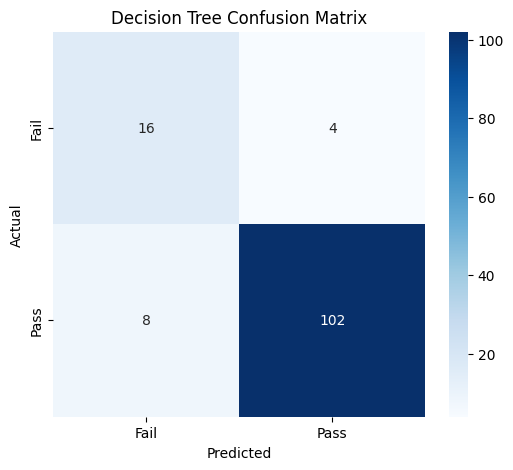

In [7]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')

plt.show()

           Feature  Importance
14              G2    0.711588
13              G1    0.138808
0              age    0.029370
8            goout    0.028792
10            Walc    0.022989
22     famsize_LE3    0.020954
49  activities_yes    0.019801
12        absences    0.012572
11          health    0.010058
50      nursery_no    0.003333
6           famrel    0.001734


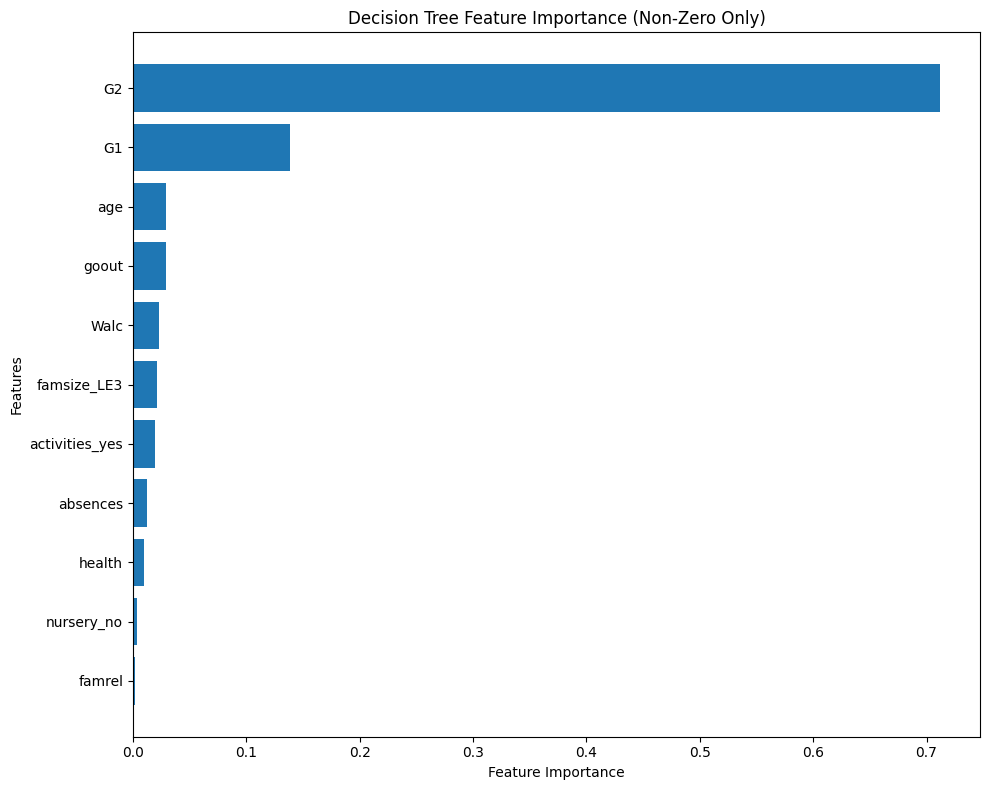

In [8]:
importances = classifier.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

# Keep only features with non-zero importance
importance_df = importance_df[importance_df['Importance'] > 0]

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance
print(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 8))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Decision Tree Feature Importance (Non-Zero Only)')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()